# Data Profiling and Quality Checks

**Profiling** is a systematic first look at a dataset: what each column contains, how complete and consistent it is, and where it can mislead a model. Feature engineering builds on this profile; a model trained on unprofiled data often learns the errors of the data instead of its patterns.

**After this lesson you can:**

1. Build a column profile: type, missing values, unique values, ranges, top values.
2. Find **disguised missing values** (`?`, `0`, `"None"`), duplicates and constant columns.
3. Check value ranges and cross-column consistency with rules.
4. Turn the profile into a list of preprocessing decisions.

**Data:** Adult census income (32,561 people, UCI, CC BY 4.0) and Ames Housing (2,930 house sales).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
RNG = 42

adult = datasets.adult()
ames = datasets.ames()
print("adult:", adult.shape, "| ames:", ames.shape)
adult.head(3)

adult: (32561, 15) | ames: (2930, 81)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K


## 1. A Column Profile

One row per column, with the facts that drive preprocessing decisions.

In [2]:
def profile(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for col in df.columns:
        s = df[col]
        num = pd.api.types.is_numeric_dtype(s)
        top = s.value_counts(dropna=True)
        rows.append({
            "column": col, "dtype": str(s.dtype), "missing_%": round(100 * s.isna().mean(), 2),
            "unique": s.nunique(dropna=True), "unique_%": round(100 * s.nunique() / len(s), 2),
            "top_value": top.index[0] if len(top) else None, "top_%": round(100 * top.iloc[0] / len(s), 1) if len(top) else None,
            "zeros_%": round(100 * (s == 0).mean(), 1) if num else None,
            "min": s.min() if num else None, "median": s.median() if num else None, "max": s.max() if num else None,
        })
    return pd.DataFrame(rows).set_index("column")

profile(adult)

,dtype,missing_%,unique,unique_%,top_value,top_%,zeros_%,min,median,max
column,,,,,,,,,,
age,int64,0.00,73,0.22,36,2.8,0.0,17.0,37.0,90.0
workclass,str,5.64,8,0.02,Private,69.7,NaN,NaN,NaN,NaN
fnlwgt,int64,0.00,21648,66.48,123011,0.0,0.0,12285.0,178356.0,1484705.0
education,str,0.00,16,0.05,HS-grad,32.3,NaN,NaN,NaN,NaN
education_num,int64,0.00,16,0.05,9,32.3,0.0,1.0,10.0,16.0
marital_status,str,0.00,7,0.02,Married-civ-spouse,46.0,NaN,NaN,NaN,NaN
occupation,str,5.66,14,0.04,Prof-specialty,12.7,NaN,NaN,NaN,NaN
relationship,str,0.00,6,0.02,Husband,40.5,NaN,NaN,NaN,NaN
race,str,0.00,5,0.02,White,85.4,NaN,NaN,NaN,NaN


What the profile shows for Adult:

- three columns with missing values (`workclass`, `occupation`, `native_country`), recorded as `?` in the raw file;
- `capital_gain` and `capital_loss` are zero for most people: very skewed, mostly empty columns;
- `education` and `education_num` look like the same information twice (checked below);
- `fnlwgt` is a census sampling weight, not a property of the person.

## 2. Disguised Missing Values

Missing values are not always `NaN`. Ames encodes them in several ways: `Lot_Frontage = 0` (a house always touches a street), and text labels such as `No_Garage` or `No_Basement`, which mean "not applicable", not "unknown".

In [3]:
amp = profile(ames)
print("NaN values in Ames:", int(ames.isna().sum().sum()))
print(f"Lot_Frontage == 0: {(ames['Lot_Frontage'] == 0).sum()} houses ({(ames['Lot_Frontage'] == 0).mean():.1%})")
no_labels = {c: ames[c].astype(str).str.startswith("No_").sum() for c in ames.select_dtypes(include="str").columns}
no_labels = pd.Series({k: v for k, v in no_labels.items() if v > 0}).sort_values(ascending=False)
print("\n'No_...' labels (not applicable) per column:")
print(no_labels.head(8).to_string())

NaN values in Ames: 0
Lot_Frontage == 0: 490 houses (16.7%)

'No_...' labels (not applicable) per column:
Pool_QC          2917
Alley            2732
Fence            2358
Fireplace_Qu     1422
Garage_Finish     159
Garage_Cond       159
Garage_Qual       159
Garage_Type       157


In [4]:
garage_cols = ["Garage_Type", "Garage_Finish", "Garage_Cars", "Garage_Area"]
no_garage = ames["Garage_Type"] == "No_Garage"
print("houses without a garage:", no_garage.sum())
print(ames.loc[no_garage, garage_cols].drop_duplicates().head())

houses without a garage: 157
   Garage_Type Garage_Finish  Garage_Cars  Garage_Area
27   No_Garage     No_Garage            0          0.0


For a house without a garage, `Garage_Area = 0` is a **true zero**, while `Lot_Frontage = 0` is an **unknown** value. The same number means different things in different columns: profiling must look at meaning, not only at numbers.

## 3. Duplicates, Constants and Redundant Columns

In [5]:
print("exact duplicate rows in Adult:", adult.duplicated().sum())
print("duplicates without the sampling weight:", adult.drop(columns="fnlwgt").duplicated().sum())

near_constant = amp[amp["top_%"] > 99].index.tolist()
print("\nAmes columns where one value covers > 99% of rows:", near_constant)

pairs = adult.groupby("education")["education_num"].agg(["nunique", "first"]).sort_values("first")
print("\neducation -> education_num is one-to-one:", (pairs["nunique"] == 1).all())
print(pairs.head(5).to_string())

exact duplicate rows in Adult: 24
duplicates without the sampling weight: 3465

Ames columns where one value covers > 99% of rows: ['Street', 'Utilities', 'Pool_Area', 'Pool_QC']

education -> education_num is one-to-one: True
           nunique  first
education                
Preschool        1      1
1st-4th          1      2
5th-6th          1      3
7th-8th          1      4
9th              1      5


`education` and `education_num` carry the same information (one is the ordered code of the other): keep one of them. Near-constant columns such as `Utilities` add almost no information and can produce unstable model behaviour on rare values.

## 4. Range and Consistency Rules

Domain knowledge gives rules that every row must satisfy. Each rule that fails points to an error or an edge case.

In [6]:
rules = {
    "age between 17 and 90": adult["age"].between(17, 90),
    "hours_per_week between 1 and 99": adult["hours_per_week"].between(1, 99),
    "capital_gain < 99999 (the cap value)": adult["capital_gain"] < 99999,
    "not (Never-worked and hours > 0 and occupation known)":
        ~((adult["workclass"] == "Never-worked") & adult["occupation"].notna()),
}
ames_rules = {
    "Year_Remod_Add >= Year_Built": ames["Year_Remod_Add"] >= ames["Year_Built"],
    "Year_Sold >= Year_Built": ames["Year_Sold"] >= ames["Year_Built"],
    "Gr_Liv_Area <= 4500 sq ft": ames["Gr_Liv_Area"] <= 4500,
    "Total_Bsmt_SF <= Gr_Liv_Area * 2": ames["Total_Bsmt_SF"] <= 2 * ames["Gr_Liv_Area"],
}
for name, rs in [("Adult", rules), ("Ames", ames_rules)]:
    print(name)
    for rule, ok in rs.items():
        print(f"  {rule:<55} failing rows: {(~ok).sum()}")

Adult


  age between 17 and 90                                   failing rows: 0
  hours_per_week between 1 and 99                         failing rows: 0
  capital_gain < 99999 (the cap value)                    failing rows: 159
  not (Never-worked and hours > 0 and occupation known)   failing rows: 0
Ames
  Year_Remod_Add >= Year_Built                            failing rows: 1
  Year_Sold >= Year_Built                                 failing rows: 1
  Gr_Liv_Area <= 4500 sq ft                               failing rows: 3
  Total_Bsmt_SF <= Gr_Liv_Area * 2                        failing rows: 0


In [7]:
print("capital_gain values at the cap:", (adult["capital_gain"] == 99999).sum())
print(ames.loc[ames["Gr_Liv_Area"] > 4500, ["Gr_Liv_Area", "Sale_Price", "Sale_Condition"]])

capital_gain values at the cap: 159
      Gr_Liv_Area  Sale_Price Sale_Condition
1498       5642.0    160000.0        Partial
2180       5095.0    183850.0        Partial
2181       4676.0    184750.0        Partial


`capital_gain = 99999` is a **top-code**: the census replaced all larger values with this cap. The three Ames houses above 4,500 sq ft are all "Partial" sales (unfinished new houses) with low prices: the dataset's author recommends removing houses above 4,000 sq ft for teaching models (Lesson 03).

## 5. Distributions at a Glance

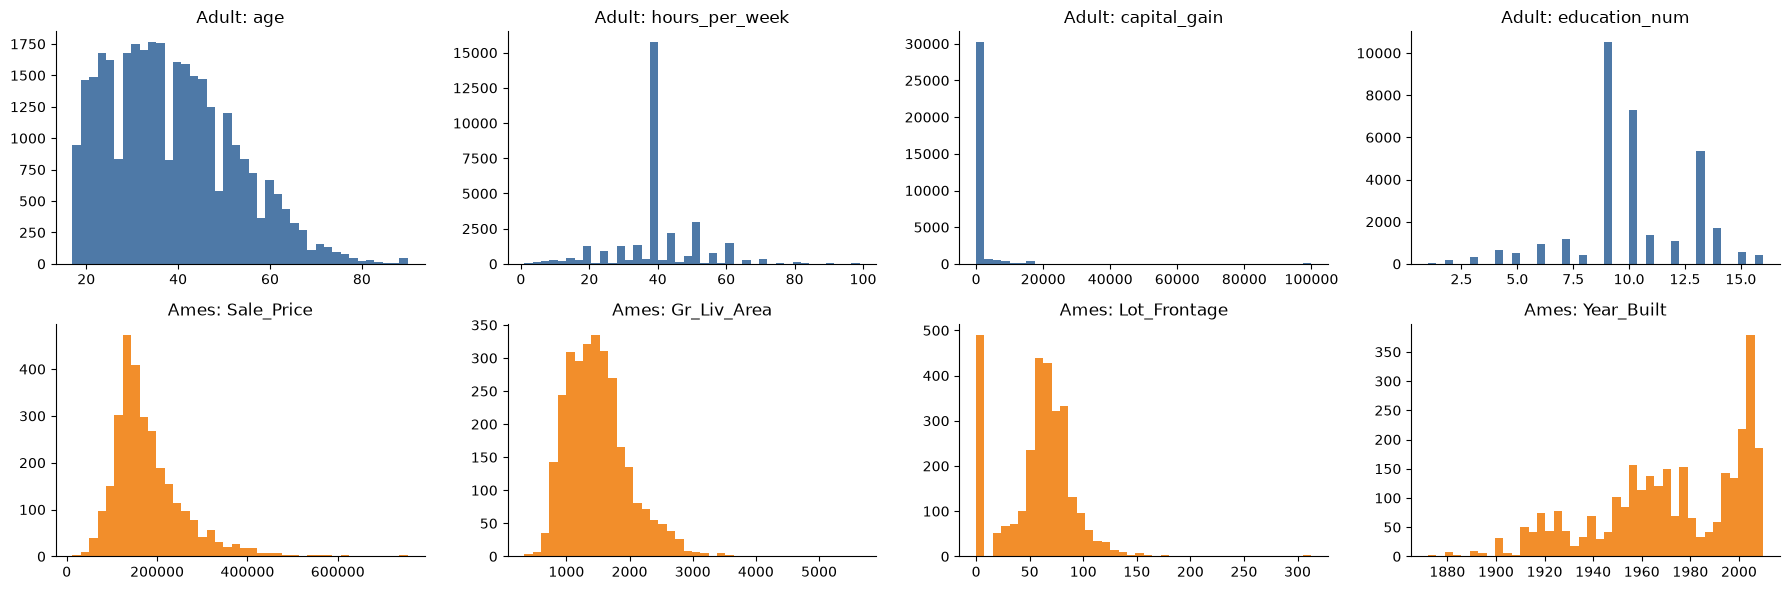

In [8]:
num = ["age", "hours_per_week", "capital_gain", "education_num"]
fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for ax, col in zip(axes[0], num):
    ax.hist(adult[col], bins=40, color="#4E79A7")
    ax.set_title(f"Adult: {col}")
for ax, col in zip(axes[1], ["Sale_Price", "Gr_Liv_Area", "Lot_Frontage", "Year_Built"]):
    ax.hist(ames[col], bins=40, color="#F28E2B")
    ax.set_title(f"Ames: {col}")
plt.tight_layout()
plt.show()

The histograms confirm the profile: `capital_gain` is a spike at 0 with a separate spike at the cap; `hours_per_week` has a peak at 40; `Lot_Frontage` has a spike at 0 (the disguised missing values); `Sale_Price` is right-skewed (Lesson 04 uses a log transform).

## 6. From Profile to Decisions

| Finding | Decision | Lesson |
| :--- | :--- | :--- |
| `?` in three Adult columns | treat as missing; impute or add a "missing" category | 02 |
| `Lot_Frontage = 0` | convert to `NaN`, then impute (by neighbourhood) | 02 |
| very large Ames houses, capped capital gains | inspect; remove or cap with a documented rule | 03 |
| skewed `Sale_Price`, `capital_gain` | log transform | 04 |
| `education` duplicated by `education_num` | keep one | 07 |
| near-constant columns | drop or group rare values | 08, 13 |
| `fnlwgt` is a sampling weight | do not use as a feature | 09 |

*Insight: Profile before you engineer: for every column, know its type, completeness, range, typical values and meaning. Most preprocessing decisions come directly from this profile, and many model errors come from skipping it.*

## Real-World Use Case or Analogy

Profiling is like a **pre-purchase inspection of a used car**: check the mileage (ranges), look for missing parts (nulls), find replaced parts that hide damage (disguised missing values), and read the service history (documentation). You do not buy the car, or train a model, before the inspection.

Data teams run profiles automatically on every new data delivery (Great Expectations, ydata-profiling, pandera, dbt tests); a sudden change in a profile is often the first sign of a broken upstream system.